# Province-level design: crop suitability and agricultural forest loss

## 1. Provinces: GFW loss tables and GADM borders

In [1]:
import os
import re
import unicodedata

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio import features

BASE = "https://raw.githubusercontent.com/AndrewEberhardt/DataScienceProject/main/data/"
PROCESSED_OUT = "../data/processed/"
FIGURES = "../figures/"

START_YEAR, END_YEAR = 2001, 2025  # GFW coverage
YEARS = list(range(START_YEAR, END_YEAR + 1))
SUITABLE = 4000  # GAEZ index threshold: class "medium" or better
CROPS = {"palm": "olp", "soy": "soy", "wheat": "whe"}  # GAEZ crop codes, wheat is the placebo crop

In [2]:
# 62-country sample (fixed), with the GFW country names used in the subnational tables
sample = (pd.read_csv(BASE + "processed/shock_panel.csv")[["iso3", "country", "region"]]
            .drop_duplicates().sort_values("iso3").reset_index(drop=True))
assert len(sample) == 62


def key(name):
    """Name used to join GFW and GADM: no accents, no spaces or punctuation, lower case."""
    ascii_name = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]", "", ascii_name.lower())


gfw_xlsx = BASE + "raw/forest/global.xlsx"
loss_wide = pd.read_excel(gfw_xlsx, sheet_name="Subnational 1 tree cover loss")
drivers = pd.read_excel(gfw_xlsx, sheet_name="Subnational 1 drivers")

loss_wide = loss_wide[(loss_wide["threshold"] == 30) & loss_wide["country"].isin(sample["country"])]
drivers = drivers[(drivers["threshold"] == 30) & drivers["country"].isin(sample["country"])]
assert loss_wide["country"].nunique() == 62

for d in (loss_wide, drivers):
    d["iso3"] = d["country"].map(sample.set_index("country")["iso3"])
    d["key"] = d["subnational1"].map(key)

# India: some states are split in several rows (areas disputed with China); they are summed
print("GFW rows:", len(loss_wide), "| provinces after summing split rows:",
      loss_wide.groupby(["iso3", "key"]).ngroups)
print(loss_wide[loss_wide.duplicated(["iso3", "key"], keep=False)][["country", "subnational1"]]
      .drop_duplicates().to_string(index=False))

GFW rows: 1282 | provinces after summing split rows: 1277
country      subnational1
  India Arunachal Pradesh
  India  Himachal Pradesh
  India       Uttarakhand


In [3]:
def gadm_path(iso3):
    """GADM 4.1 province borders of one country, read from the zipped GeoJSON."""
    url = BASE + f"raw/gadm/gadm41_{iso3}_1.json.zip"
    return "zip+" + url if url.startswith("http") else "zip://" + url


frames = []
for iso3 in sample["iso3"]:
    g = gpd.read_file(gadm_path(iso3))[["GID_0", "NAME_1", "geometry"]]
    g["iso3"] = iso3  # disputed areas (GID_0 Z01-Z09) inside the India file stay with India
    frames.append(g)
gadm = pd.concat(frames, ignore_index=True)
print("Disputed areas kept with India:", gadm.loc[gadm["GID_0"].str.match(r"^Z\d"), "NAME_1"].tolist())
gadm["geometry"] = gadm.geometry.make_valid()  # a few GADM polygons are not valid

gadm["key"] = gadm["NAME_1"].map(key)
provinces = gpd.GeoDataFrame(gadm.dissolve(["iso3", "key"], as_index=False)[["iso3", "key", "NAME_1", "geometry"]],
                             crs="EPSG:4326")

# Every GFW province must have exactly one GADM polygon and the reverse
gfw_keys = loss_wide[["iso3", "key"]].drop_duplicates()
check = gfw_keys.merge(provinces[["iso3", "key"]], on=["iso3", "key"], how="outer", indicator=True)
print(check["_merge"].value_counts().to_dict())
assert (check["_merge"] == "both").all()
provinces = provinces.merge(sample, on="iso3").sort_values(["iso3", "key"]).reset_index(drop=True)
provinces["province_id"] = provinces["iso3"] + "_" + provinces["key"]
print("Provinces:", len(provinces), "| per country:", provinces.groupby("iso3").size().describe()[["min", "50%", "max"]].to_dict())

Disputed areas kept with India: ['ArunachalPradesh', 'HimachalPradesh', 'HimachalPradesh', 'JammuandKashmir', 'Uttarakhand', 'Uttarakhand']


/opt/anaconda3/envs/DataScienceClass2026/lib/python3.11/site-packages/shapely/set_operations.py:553: RuntimeWarning: invalid value encountered in unary_union
  return lib.unary_union(collections, **kwargs)


{'both': 1277, 'left_only': 0, 'right_only': 0}
Provinces: 1277 | per country: {'min': 4.0, '50%': 16.0, 'max': 81.0}


## 2. Crop suitability by province (GAEZ)

In [4]:
def read_raster(path):
    """Read a GAEZ GeoTIFF, nodata as NaN."""
    with rasterio.open(BASE + path) as src:
        values = src.read(1).astype(float)
        if src.nodata is not None:
            values[values == src.nodata] = np.nan
        return values, src.transform, src.shape


grids = {}
for crop, code in CROPS.items():
    grids[crop], transform, shape = read_raster(f"raw/gaez/sxHr_{code}.tif")
water_class, _, _ = read_raster("raw/gaez/siLr_olp.tif")  # class 9 = inland water
land_cells = ~np.isnan(grids["palm"]) & (water_class != 9)
assert all(not np.isnan(g[land_cells]).any() for g in grids.values())

# Area of each 5 arc-minute cell (ha)
R_EARTH = 6_371_007.2
res = abs(transform.e)
lat_top = transform.f - res * np.arange(shape[0])
cell_m2 = R_EARTH ** 2 * np.deg2rad(res) * (np.sin(np.deg2rad(lat_top)) - np.sin(np.deg2rad(lat_top - res)))
cell_ha = np.repeat((cell_m2 / 10_000)[:, None], shape[1], axis=1)

In [5]:
def stats(mask):
    """Area-weighted suitability measures over the GAEZ land cells in mask."""
    area = cell_ha[mask]
    land = area.sum()
    row = {"n_cells": int(mask.sum()), "land_area_gaez_ha": land}
    for crop in CROPS:
        g = grids[crop][mask]
        row[f"suit_{crop}"] = area[g >= SUITABLE].sum() / land if land > 0 else np.nan
        row[f"suit_{crop}_mean"] = (area * g).sum() / land / 10_000 if land > 0 else np.nan
    return row


# A cell belongs to the province containing its center
ids_center = features.rasterize(((geom, i + 1) for i, geom in enumerate(provinces.geometry)),
                                out_shape=shape, transform=transform, fill=0, dtype="int32")
rows = [stats(land_cells & (ids_center == i + 1)) for i in range(len(provinces))]

# Very small provinces (islands, capital districts): every cell they touch, province by province
MIN_CELLS = 5
few = [i for i, r in enumerate(rows) if r["n_cells"] < MIN_CELLS]
for i in few:
    touched = features.rasterize([(provinces.geometry.iloc[i], 1)], out_shape=shape, transform=transform,
                                 fill=0, all_touched=True, dtype="uint8").astype(bool)
    rows[i] = stats(land_cells & touched)
print(f"Provinces with fewer than {MIN_CELLS} cells, measured with all touched cells:", len(few))

provinces = provinces.join(pd.DataFrame(rows, index=provinces.index))
print("Provinces with no GAEZ land cell:", provinces.loc[provinces["n_cells"] == 0, "province_id"].tolist())
provinces[[c for c in provinces.columns if c.startswith("suit_")]].describe().round(3)

Provinces with fewer than 5 cells, measured with all touched cells: 42
Provinces with no GAEZ land cell: ['AUS_ashmoreandcartierislands', 'AUS_coralseaislandsterritory', 'MWI_likoma']


,suit_palm,suit_palm_mean,suit_soy,suit_soy_mean,suit_wheat,suit_wheat_mean
count,1274.000,1274.000,1274.000,1274.000,1274.000,1274.000
mean,0.135,0.142,0.530,0.406,0.154,0.132
std,0.250,0.171,0.372,0.228,0.283,0.184
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.000,0.162,0.222,0.000,0.000
50%,0.000,0.064,0.562,0.420,0.000,0.024
75%,0.160,0.258,0.913,0.591,0.160,0.229
max,1.000,0.742,1.000,0.944,1.000,0.810


## 3. Province panel

In [6]:
# Total tree cover loss by province and year (wide to long), split rows summed
loss_cols = [f"tc_loss_ha_{y}" for y in YEARS]
base = (loss_wide.groupby(["iso3", "key"], as_index=False)[["area_ha", "extent_2000_ha"] + loss_cols].sum())
total = (base.melt(id_vars=["iso3", "key"], value_vars=loss_cols, var_name="year", value_name="total_loss_ha")
             .assign(year=lambda d: d["year"].str[-4:].astype(int)))

# Loss with permanent agriculture as dominant driver (provinces without rows have no such loss)
agri = (drivers[drivers["driver"] == "Permanent agriculture"]
        .groupby(["iso3", "key", "year"], as_index=False)["tc_loss_ha"].sum()
        .rename(columns={"tc_loss_ha": "agri_loss_ha"}))

panel = (total.merge(agri, on=["iso3", "key", "year"], how="left", validate="one_to_one")
              .merge(base[["iso3", "key", "area_ha", "extent_2000_ha"]], on=["iso3", "key"], validate="many_to_one"))
panel["agri_loss_ha"] = panel["agri_loss_ha"].fillna(0.0)
assert (panel["agri_loss_ha"] <= panel["total_loss_ha"] + 1).all()
assert len(panel) == len(provinces) * len(YEARS)

# Check: provinces add up to the national GFW totals used in notebooks 1 to 5
national = pd.read_csv(BASE + "processed/shock_panel.csv")[["iso3", "year", "loss_ha", "agri_loss_ha"]]
sums = panel.groupby(["iso3", "year"], as_index=False)[["total_loss_ha", "agri_loss_ha"]].sum()
cmp_nat = sums.merge(national, on=["iso3", "year"], suffixes=("", "_national"))
for prov_col, nat_col in [("total_loss_ha", "loss_ha"), ("agri_loss_ha", "agri_loss_ha_national")]:
    ratio = cmp_nat[prov_col].sum() / cmp_nat[nat_col].sum()
    worst = (cmp_nat.groupby("iso3")[[prov_col, nat_col]].sum().pipe(lambda d: d[prov_col] / d[nat_col] - 1)
             .abs().sort_values(ascending=False).head(3).round(4).to_dict())
    print(f"{prov_col}: provinces / national = {ratio:.4f} | largest country gaps: {worst}")

total_loss_ha: provinces / national = 1.0000 | largest country gaps: {'VUT': 0.0001, 'TWN': 0.0001, 'BTN': 0.0001}
agri_loss_ha: provinces / national = 1.0000 | largest country gaps: {'VUT': 0.0018, 'FJI': 0.0011, 'BTN': 0.0007}


In [7]:
# Rates as % of tree cover in 2000; provinces with almost no forest are dropped (rate not meaningful)
MIN_FOREST_HA = 1000
no_forest = base.loc[base["extent_2000_ha"] < MIN_FOREST_HA, ["iso3", "key", "extent_2000_ha"]]
print(f"Provinces with less than {MIN_FOREST_HA} ha of tree cover in 2000 (dropped):", len(no_forest),
      "| share of sample tree cover:", round(no_forest["extent_2000_ha"].sum() / base["extent_2000_ha"].sum(), 6))

panel = panel.merge(no_forest[["iso3", "key"]], on=["iso3", "key"], how="left", indicator=True)
panel = panel[panel["_merge"] == "left_only"].drop(columns="_merge")
for name in ["agri", "total"]:
    panel[f"{name}_rate"] = panel[f"{name}_loss_ha"] / panel["extent_2000_ha"] * 100
    panel[f"y_{name}"] = np.arcsinh(panel[f"{name}_rate"])

KEEP = (["province_id", "iso3", "country", "region", "NAME_1", "n_cells", "land_area_gaez_ha"]
        + [c for c in provinces.columns if c.startswith("suit_")])
panel = (panel.merge(provinces[["key"] + KEEP], on=["iso3", "key"], validate="many_to_one")
              .rename(columns={"NAME_1": "province"})
              .sort_values(["province_id", "year"]).reset_index(drop=True))
assert panel.groupby("province_id").size().eq(len(YEARS)).all()  # balanced
assert panel.filter(like="suit_").notna().all().all()
print("Panel:", panel.shape, "| provinces:", panel["province_id"].nunique(), "| countries:", panel["iso3"].nunique())

Provinces with less than 1000 ha of tree cover in 2000 (dropped): 50 | share of sample tree cover: 5e-06
Panel: (30675, 23) | provinces: 1227 | countries: 62


In [8]:
OUT_COLS = (["province_id", "iso3", "country", "region", "province", "year", "area_ha", "extent_2000_ha",
             "land_area_gaez_ha", "n_cells"] + sorted(c for c in panel.columns if c.startswith("suit_"))
            + ["total_loss_ha", "agri_loss_ha", "total_rate", "agri_rate", "y_total", "y_agri"])
if os.path.isdir(PROCESSED_OUT):
    panel[OUT_COLS].to_csv(PROCESSED_OUT + "province_panel.csv", index=False)
panel[OUT_COLS].head()

,province_id,iso3,country,region,province,year,area_ha,extent_2000_ha,land_area_gaez_ha,n_cells,...,suit_soy,suit_soy_mean,suit_wheat,suit_wheat_mean,total_loss_ha,agri_loss_ha,total_rate,agri_rate,y_total,y_agri
0,AGO_bengo,AGO,Angola,Africa,Bengo,2001,3436440,1962851,3.434456e+06,405,...,0.886487,0.519102,0.014812,0.067935,17934,12041.0,0.913671,0.613444,0.818994,0.580319
1,AGO_bengo,AGO,Angola,Africa,Bengo,2002,3436440,1962851,3.434456e+06,405,...,0.886487,0.519102,0.014812,0.067935,6441,4664.0,0.328145,0.237614,0.322524,0.235433
2,AGO_bengo,AGO,Angola,Africa,Bengo,2003,3436440,1962851,3.434456e+06,405,...,0.886487,0.519102,0.014812,0.067935,4908,3140.0,0.250044,0.159971,0.247510,0.159297
3,AGO_bengo,AGO,Angola,Africa,Bengo,2004,3436440,1962851,3.434456e+06,405,...,0.886487,0.519102,0.014812,0.067935,2826,1137.0,0.143974,0.057926,0.143481,0.057894
4,AGO_bengo,AGO,Angola,Africa,Bengo,2005,3436440,1962851,3.434456e+06,405,...,0.886487,0.519102,0.014812,0.067935,1547,676.0,0.078814,0.034440,0.078733,0.034433


## 4. Descriptive statistics

In [9]:
def describe(group):
    prov = group.drop_duplicates("province_id")
    return pd.Series({
        "countries": group["iso3"].nunique(),
        "provinces": len(prov),
        "mean_agri_rate_pct": group["agri_rate"].mean(),
        "median_agri_rate_pct": group["agri_rate"].median(),
        "share_zero_agri": (group["agri_loss_ha"] == 0).mean(),
        "agri_share_of_loss": group["agri_loss_ha"].sum() / group["total_loss_ha"].sum(),
        "mean_suit_palm": prov["suit_palm"].mean(),
        "mean_suit_soy": prov["suit_soy"].mean(),
        "mean_suit_wheat": prov["suit_wheat"].mean(),
    })


summary = pd.DataFrame({r: describe(g) for r, g in panel.groupby("region")}).T
summary.loc["All provinces"] = describe(panel)
summary[["countries", "provinces"]] = summary[["countries", "provinces"]].astype(int)
summary.round(3)

,countries,provinces,mean_agri_rate_pct,median_agri_rate_pct,share_zero_agri,agri_share_of_loss,mean_suit_palm,mean_suit_soy,mean_suit_wheat
Africa,24,393,0.375,0.179,0.012,0.414,0.116,0.718,0.291
Asia-Pacific,19,472,0.324,0.103,0.050,0.545,0.131,0.411,0.058
Latin America & Caribbean,19,362,0.331,0.216,0.027,0.736,0.176,0.487,0.132
All provinces,62,1227,0.343,0.158,0.031,0.601,0.139,0.532,0.155


In [10]:
# How much of the variation in suitability is within countries (what country x year FE leave us)?
prov = panel.drop_duplicates("province_id")
rows = []
for crop in CROPS:
    s = prov[f"suit_{crop}"]
    within = s - prov.groupby("iso3")[f"suit_{crop}"].transform("mean")
    rows.append({"crop": crop, "sd_total": s.std(), "sd_within_country": within.std(),
                 "share_variance_within": within.var() / s.var(),
                 "countries_with_within_variation": int((prov.groupby("iso3")[f"suit_{crop}"].std() > 0.05).sum())})
pd.DataFrame(rows).set_index("crop").round(3)

,sd_total,sd_within_country,share_variance_within,countries_with_within_variation
crop,,,,
palm,0.253,0.192,0.579,41
soy,0.371,0.268,0.524,59
wheat,0.282,0.187,0.440,35


In [11]:
# Correlation between crop suitabilities across provinces (placebo crop must differ from palm and soy)
prov[["suit_palm", "suit_soy", "suit_wheat"]].corr().round(2)

,suit_palm,suit_soy,suit_wheat
suit_palm,1.00,-0.01,-0.29
suit_soy,-0.01,1.00,0.31
suit_wheat,-0.29,0.31,1.00


/opt/anaconda3/envs/DataScienceClass2026/lib/python3.11/site-packages/shapely/constructive.py:1177: RuntimeWarning: invalid value encountered in simplify_preserve_topology
  return lib.simplify_preserve_topology(geometry, tolerance, **kwargs)


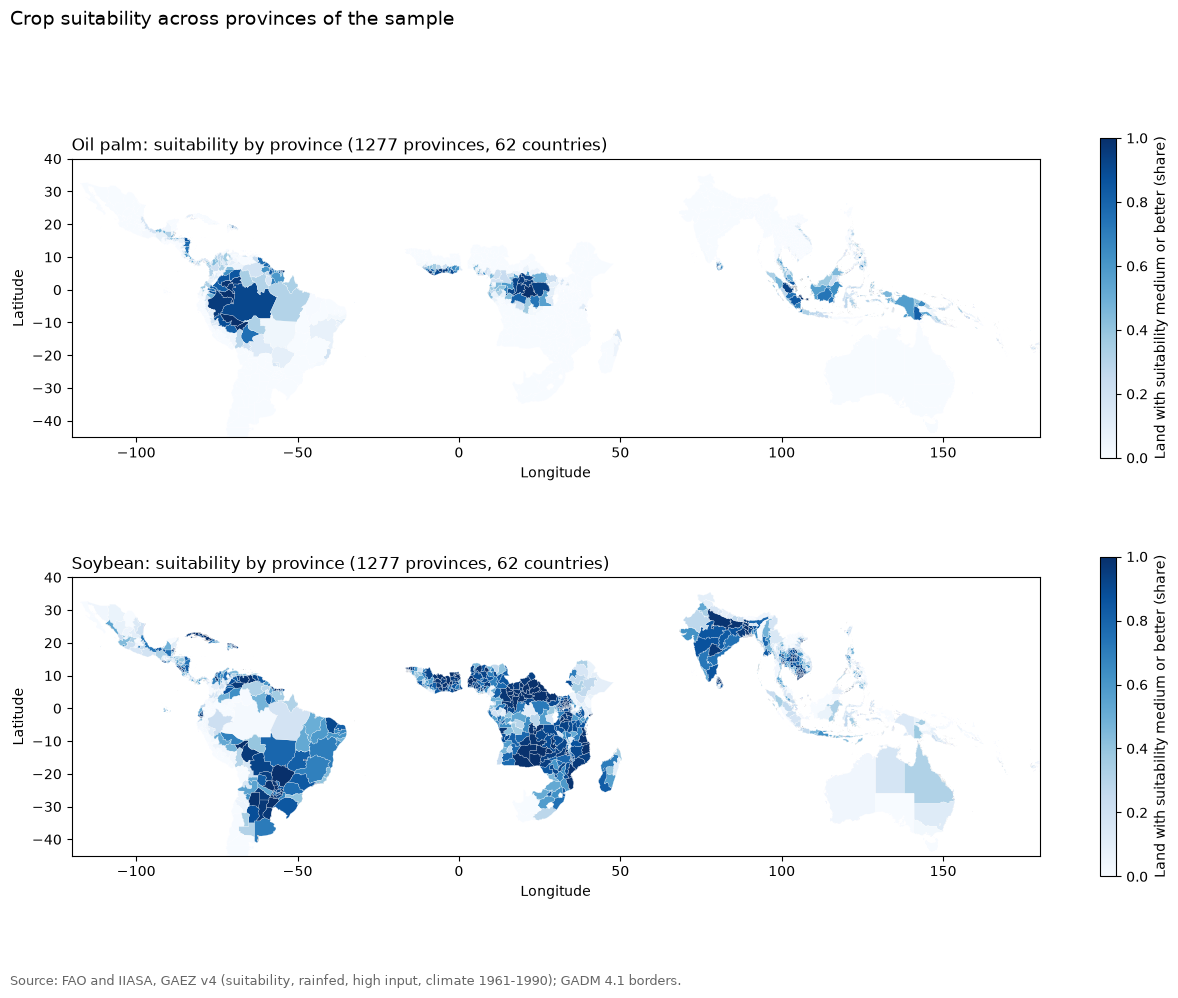

In [12]:
# Map of province suitability for oil palm and soybean
SOURCE = "Source: FAO and IIASA, GAEZ v4 (suitability, rainfed, high input, climate 1961-1990); GADM 4.1 borders."
TITLES = {"palm": "Oil palm", "soy": "Soybean"}
shapes = provinces.copy()
shapes["geometry"] = shapes.geometry.simplify(0.05)

fig, axes = plt.subplots(2, 1, figsize=(13, 10))
for ax, crop in zip(axes, ["palm", "soy"]):
    shapes.plot(column=f"suit_{crop}", ax=ax, cmap="Blues", vmin=0, vmax=1, edgecolor="#ffffff", linewidth=0.15,
                legend=True, legend_kwds={"label": "Land with suitability medium or better (share)", "shrink": 0.7})
    ax.set_title(f"{TITLES[crop]}: suitability by province ({len(shapes)} provinces, 62 countries)",
                 loc="left", fontsize=12)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_xlim(-120, 180)
    ax.set_ylim(-45, 40)
fig.suptitle("Crop suitability across provinces of the sample", x=0.01, ha="left", fontsize=14)
fig.text(0.01, 0.005, SOURCE, fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.03, 1, 0.97))
if os.path.isdir(FIGURES):
    fig.savefig(FIGURES + "province_suitability_map.png", dpi=200, bbox_inches="tight")
plt.show()